In [1]:
import numpy as np
import pandas as pd
import os 
from pathlib import Path
print("현재 위치:", os.getcwd())

현재 위치: /Users/yuri.seo/Documents/GitHub/webnovel-pass-ab-test/notebooks


In [2]:
#데이터 불러오기

ROOT = Path.cwd().parent
DATA = ROOT / "data" / "clean"


coin_transactions = pd.read_csv(DATA / "coin_transactions.csv.gz",parse_dates=['txn_at'])
daily_reading = pd.read_csv(DATA / "daily_reading.csv.gz",parse_dates = ['read_date'])
exposures = pd.read_csv(DATA / "exposures.csv.gz",parse_dates = ['exposed_at'])
subscription_events = pd.read_csv(DATA / "subscription_events.csv.gz",parse_dates = ['event_at'])
titles = pd.read_csv(DATA / "titles.csv.gz")
users = pd.read_csv(DATA / "users.csv.gz",parse_dates = ['signup_date'])



# 각 테이블 정보 확인을 위해 딕셔너리 생성
table_info = {"coin_transactions":coin_transactions,
      "daily_reading":daily_reading,
     "exposures":exposures,
     "subscription_events":subscription_events,
     "titles":titles,
     "users":users}

for key, val in table_info.items():
    print(key, val.shape)


coin_transactions (823238, 6)
daily_reading (1859866, 6)
exposures (314922, 4)
subscription_events (60367, 5)
titles (6300, 4)
users (314922, 9)


# 전환율 확인

In [3]:
# variant별 전환율 구하기 

# base 테이블 만들기
# 전체 유저 | variant | started_trial | 결제 여부 (converted)

base = table_info["users"][["user_id"]]

base = base.merge(
    table_info["exposures"][["user_id","variant"]],
    on = "user_id",
    how = "left"
)


# base에 trial True =1 False = 0 으로 추가하기. 

# events로 먼저 정리 
events = table_info["subscription_events"].copy()

events["start_trial"] = (events["event_type"] == 'trial_start').astype(int)
events["converted"] = (events["event_type"] == 'payment').astype(int)
events

# user별 그룹화 
user_events = events.groupby("user_id")[["start_trial","converted"]].max().reset_index()

# Join
base = base.merge(
    user_events[["user_id","start_trial","converted"]],
    on = "user_id",
    how = "left"
)

# 결측치 0으로 변환 
base[["start_trial","converted"]] = base[["start_trial","converted"]].fillna(0).astype(int)

len(base)


# 각 그룹별 전환율 구하기
result_st = base.groupby("variant")["start_trial"].mean()                                       ## 체험율
result_st_convert = base.loc[base["start_trial"]==1].groupby("variant")["converted"].mean()     ## 체험시작 기준 전환율 (start_trial)
result_e_convert = base.groupby("variant")["converted"].mean()                                  ## 노출자 기준 전환율 (exposed)
result_user_cnt = base.groupby("variant")["user_id"].nunique()                                ## 전체 유저 수
result_st_cnt = base.groupby("variant")["start_trial"].sum()                                    ## 체험 유저 수
result_convert_cnt = base.groupby("variant")["converted"].sum()                                 ## 구매 유저 수


result_d = pd.DataFrame({
    "노출 유저 수" : result_user_cnt,
    "체험 유저 수" : result_st_cnt,
    "구매 유저 수" : result_convert_cnt,
    "체험 시작률"  : result_st,
    "노출 기준 전환율" : result_e_convert,
    "체험 시작 기준 전환율" : result_st_convert
})
result_d = result_d.T
result_d


variant,A,B
노출 유저 수,157461.000000,157461.000000
체험 유저 수,12323.000000,13805.000000
구매 유저 수,3602.000000,3977.000000
체험 시작률,0.078261,0.087673
노출 기준 전환율,0.022876,0.025257
체험 시작 기준 전환율,0.292299,0.288084


In [4]:
# ── 비율 행만 %로 바꾸기 ──
rate_rows = ["체험 시작률", "노출 기준 전환율", "체험 시작 기준 전환율"]
count_rows = ["노출 유저 수", "체험 유저 수", "구매 유저 수"]

result_d.loc[rate_rows] = result_d.loc[rate_rows] * 100

# ── 차이와 상대 uplift ──
# 절대 차이: B - A  (비율 행은 %p, 인원 행은 명)
result_d["차이(B-A)"] = result_d["B"] - result_d["A"]

# 상대 uplift: (B - A) / A × 100  → 비율 행에만 의미가 있음
result_d["상대 uplift(%)"] = (result_d["B"] - result_d["A"]) / result_d["A"] * 100
result_d.loc[count_rows, "상대 uplift(%)"] = np.nan   # 인원 수의 uplift는 의미 없으니 비움

# ── 보기 좋게 반올림 ──
result_d = result_d.round(2)
result_d

variant,A,B,차이(B-A),상대 uplift(%)
노출 유저 수,157461.00,157461.00,0.00,NaN
체험 유저 수,12323.00,13805.00,1482.00,NaN
구매 유저 수,3602.00,3977.00,375.00,NaN
체험 시작률,7.83,8.77,0.94,12.03
노출 기준 전환율,2.29,2.53,0.24,10.41
체험 시작 기준 전환율,29.23,28.81,-0.42,-1.44


### 라운드 1 결과: 첫인상

**관찰**
- 체험 시작률: A 7.83% vs B 8.77% → B가 0.94%p 높음 (상대 +12.0%)
- 노출 기준 전환율: A 2.29% vs B 2.53% → B가 0.24%p 높음 (상대 +10.4%)
- 체험 시작 기준 전환율: A 29.23% vs B 28.81% → A가 0.42%p 높음 (상대 -1.4%)

**첫인상**
- 어떤 전환율을 보느냐에 따라 우세한 그룹이 바뀜
- 노출 기준으로는 B가 나아 보이고, 체험 시작 기준으로는 A가 근소하게 나아 보임
- 세 지표 중 차이가 가장 큰 것은 체험 시작률 (상대 +12.0%)

**기준마다 결과가 다른 이유 (가설)**
- 노출 기준 전환율 = 체험 시작률 × 체험 시작 기준 전환율
- B는 "14일 무료" 문구로 체험을 더 많이 끌어왔고(체험 시작률 ↑), 그중 결제로 이어진 비율은 A와 비슷하거나 조금 낮음
- 그 결과 노출 기준으로는 B가 앞서고, 체험 시작 기준으로는 A가 앞섬

**남은 의문 → 라운드 2·3에서 확인**
1. 차이가 모두 1%p 미만. 우연히 생긴 차이일 가능성은? → 통계 검정 필요
2. 노출 유저 수가 A, B 정확히 같음. 배정이 제대로 이뤄졌나? → SRM 점검
3. 두 그룹은 실험 전에 비슷한 사람들이었나? → 사전 균형 점검
4. B가 체험을 더 많이 끌어왔다면, B의 체험 시작자에는 A라면 체험하지 않았을 사람이 섞여 있음. A·B의 체험 시작자를 그대로 비교해도 공정한가? → 선택 편향 점검
5. 출시 판단에는 어떤 전환율을 써야 하나? 각 지표는 어떤 질문에 답하는 숫자인가?

## 라운드 2. 실험 점검: 이 실험을 믿을 수 있는가

### 왜 점검부터 하는가
- 라운드 1에서 본 차이를 "B(14일 체험) 때문"이라고 말하려면, 두 그룹이 체험 기간 외에는 같은 조건이어야 함
- 이 전제가 깨져 있으면 검정을 아무리 정교하게 해도 결론을 신뢰할 수 없음
- 따라서 검정(라운드 3) 전에 아래 두 가지를 먼저 확인

| 점검 | 질문 | 실패 시 |
| --- | --- | --- |
| SRM | 계획한 비율(50:50)대로 배정됐는가 | 배정 시스템·로그 오류 의심 → 결과 전체 보류 |
| 사전 균형 | 실험 전 행동이 두 그룹에서 비슷한가 | 처음부터 다른 집단 → 차이의 원인을 B로 볼 수 없음 |

---

### 2-1. SRM (Sample Ratio Mismatch)

**질문**
- 50:50 배정이었다면 현재 관찰된 인원 비율이 나올 만한가

**고민: A·B 인원이 정확히 같은데 검정이 필요한가**
- 점검은 숫자를 보고 할지 말지 정하는 것이 아니라 항상 같은 절차로 수행
- 다른 실험에서 157,461 vs 156,890처럼 어긋났을 때 "이 정도면 괜찮은가"를 판단하는 기준이 검정
- 정확히 동일한 인원은 무작위 배정에서 흔하지 않음 (15만 명씩 나누면 보통 수백 명 차이 발생)
  - 실무라면 강제 균등 배정 방식인지 확인할 대상
  - SRM은 비율이 어긋난 것을 찾는 검정이므로 이 경우 실패 사유는 아님
  - 본 데이터에서는 생성 과정에서 우연히 일치한 것으로 판단

**후보 방법**

| 방법 | 내용 | 판단 |
| --- | --- | --- |
| 카이제곱 적합도 검정 | 관찰 인원과 기대 인원(전체의 50%씩) 비교 | ✅ 채택. SRM 점검의 표준 방법, 그룹이 3개 이상이어도 동일하게 적용 가능 |
| 이항 검정 | "A일 확률 0.5"인 시행 결과로 간주 | △ 두 그룹에서는 결과가 사실상 동일. 확장성 때문에 카이제곱 선택 |
| 비율 눈으로 확인 | 50.1% vs 49.9%면 괜찮다고 판단 | ✗ 판단 기준이 없음. 31만 명 규모에서는 0.3%p 차이도 이상 신호일 수 있음 |

**판단 기준: p < 0.001이면 SRM**
- 일반적인 0.05보다 엄격하게 설정 (실험 설계서 7장)
- SRM은 "실험 전체를 버린다"는 무거운 결정 → 우연한 흔들림으로 실험을 버리는 손실이 큼
- 실제 배정 오류는 보통 수천 명 단위로 어긋나므로 엄격한 기준으로도 충분히 탐지됨

---

### 2-2. 사전 균형 (Pre-experiment balance)

**질문**
- 실험 전에 이미 정해진 값들이 두 그룹에서 비슷한가
- 실험 전 값은 B의 영향을 받을 수 없으므로, 여기서 차이가 크면 배정 자체가 치우쳤다는 신호

**비교 대상**

| 유형 | 컬럼 |
| --- | --- |
| 숫자 | pre30_serial_reads, pre30_completed_reads, pre30_free_reads, pre30_coin_spend |
| 범주 | age_group, acquisition_channel, preferred_genre, platform |

**고민: t-검정으로 평균을 비교하면 되지 않나**
- 표본이 약 31만 명으로 매우 큼
- 표본이 크면 실질적으로 무의미한 작은 차이도 p-value가 0.05 아래로 떨어짐
  - 예: 실험 전 30일 열람이 A 45.1화, B 45.3화여도 "유의한 차이"로 나올 수 있음
  - 그렇다고 두 그룹이 다른 집단이라고 보기는 어려움
- 따라서 "차이가 있는가(p-value)"보다 "차이가 얼마나 큰가(효과 크기)"로 판단

**후보 방법**

| 방법 | 묻는 것 | 판단 |
| --- | --- | --- |
| t-검정 p-value | 차이가 0인가 | △ 표본이 크면 사소한 차이도 유의하게 나옴. 참고용 |
| 표준화 평균 차이 (SMD) | 차이가 분포 폭에 비해 얼마나 큰가 | ✅ 숫자 컬럼에 채택 |
| 그룹별 비율 비교 + 카이제곱 독립성 검정 | 범주 분포가 그룹마다 다른가 | ✅ 범주 컬럼에 채택. 비율 차이를 함께 확인 |

**SMD (Standardized Mean Difference)**
- SMD = (B 평균 − A 평균) ÷ 합친 표준편차
- 합친 표준편차 = √((A 분산 + B 분산) / 2)
- 단위가 사라져 열람 회차·결제 금액처럼 단위가 다른 컬럼을 같은 기준으로 비교 가능
- 판단 기준: |SMD| < 0.1이면 균형

**범주 컬럼 확인 방법**
- 그룹별 비율: crosstab(행 = variant, normalize = "index")로 그룹마다 합이 1이 되도록 구성
- 검정: 비율이 아닌 인원수 교차표로 카이제곱 독립성 검정
- 표본이 큰 만큼 p-value보다 비율 차이(%p) 크기를 함께 보고 판단

---

### 체크포인트
- [ ] SRM 카이제곱 p ≥ 0.001
- [ ] 숫자 컬럼 4개 |SMD| < 0.1
- [ ] 범주 컬럼 그룹 간 비율 차이 확인

In [5]:
from scipy.stats import chisquare

# ── 설정: 배정 비율과 판단 기준 (실험 설계서 7장) ──
ALLOCATION = {"A": 0.5, "B": 0.5}    # 계획한 배정 비율
SRM_ALPHA = 0.001                    # SRM 판단 기준 (일반 기준 0.05보다 엄격)

# ── 관찰 인원 vs 기대 인원 ──
observed = base["variant"].value_counts().reindex(ALLOCATION.keys())   # A, B 순서 고정
total = observed.sum()
expected = pd.Series({g: total * r for g, r in ALLOCATION.items()})

# ── 카이제곱 적합도 검정 ──
srm = chisquare(f_obs=observed, f_exp=expected)

# ── 결과 표 ──
srm_table = pd.DataFrame({
    "관찰 인원": observed,
    "기대 인원": expected,
    "관찰 비율(%)": (observed / total * 100).round(3),
    "계획 비율(%)": pd.Series(ALLOCATION) * 100,
})
display(srm_table)

# ── 판단 ──
print(f"카이제곱 통계량: {srm.statistic:.4f}")
print(f"p-value: {srm.pvalue:.4f}")

if srm.pvalue < SRM_ALPHA:
    print(f"⚠️ SRM 발생 (p < {SRM_ALPHA}) → 배정 오류 의심, 결과 해석 보류")
else:
    print(f"✅ SRM 없음 (p ≥ {SRM_ALPHA}) → 계획한 비율대로 배정됨")

,관찰 인원,기대 인원,관찰 비율(%),계획 비율(%)
A,157461,157461.0,50.0,50.0
B,157461,157461.0,50.0,50.0


카이제곱 통계량: 0.0000
p-value: 1.0000
✅ SRM 없음 (p ≥ 0.001) → 계획한 비율대로 배정됨


**SRM 결과**
- A 157,461명, B 157,461명 (50.000% : 50.000%)
- 카이제곱 통계량 0.0, p = 1.0 → SRM 없음
- 참고: 인원이 정확히 일치하는 것은 무작위 배정에서 드문 경우. 실무라면 강제 균등 배정 여부를 확인할 대상이나, 본 데이터는 생성 과정의 우연한 일치로 판단

In [6]:
# ── 비교할 컬럼과 판단 기준 ──
NUM_COLS = ["pre30_serial_reads", "pre30_completed_reads",
            "pre30_free_reads", "pre30_coin_spend"]                      # 숫자: SMD로 비교
CAT_COLS = ["age_group", "acquisition_channel", "preferred_genre", "platform"]  # 범주: 비율 차이로 비교
SMD_THRESHOLD = 0.1                                                        # |SMD| < 0.1 이면 균형

# ── 배정 정보(base)에 실험 전 정보 붙이기 ──
# platform은 exposures에, 나머지는 users에 있음
balance_df = (
    base[["user_id", "variant"]]
    .merge(users[["user_id"] + NUM_COLS + ["age_group", "acquisition_channel", "preferred_genre"]],
           on="user_id", how="left")
    .merge(exposures[["user_id", "platform"]], on="user_id", how="left")
)

# 확인: 행 수 유지, 결측 없음
print(f"행 수: {len(balance_df):,}  /  결측: {balance_df.isna().sum().sum()}")

행 수: 314,922  /  결측: 0


In [7]:
from scipy.stats import ttest_ind

group_a = balance_df[balance_df["variant"] == "A"]
group_b = balance_df[balance_df["variant"] == "B"]

rows = []
for col in NUM_COLS:
    # 합친 표준편차: 두 그룹 분산의 평균에 제곱근
    pooled_sd = np.sqrt((group_a[col].var() + group_b[col].var()) / 2)
    smd = (group_b[col].mean() - group_a[col].mean()) / pooled_sd

    # 참고용 t-검정 (표본이 커서 판단 기준으로는 쓰지 않음)
    t_p = ttest_ind(group_a[col], group_b[col], equal_var=False).pvalue

    rows.append({
        "컬럼": col,
        "A 평균": group_a[col].mean(),
        "B 평균": group_b[col].mean(),
        "SMD": smd,
        "t-검정 p (참고)": t_p,
        "균형": "OK" if abs(smd) < SMD_THRESHOLD else "⚠️",
    })

num_balance = pd.DataFrame(rows).round(4)
num_balance

,컬럼,A 평균,B 평균,SMD,t-검정 p (참고),균형
0,pre30_serial_reads,52.0084,52.0659,0.0015,0.6726,OK
1,pre30_completed_reads,68.2905,68.3620,0.0008,0.8240,OK
2,pre30_free_reads,20.9136,20.8087,-0.0061,0.0855,OK
3,pre30_coin_spend,3162.4313,3157.3317,-0.0007,0.8551,OK


In [8]:
from scipy.stats import chi2_contingency

rows = []
for col in CAT_COLS:
    counts = pd.crosstab(balance_df["variant"], balance_df[col])                         # 인원수 (검정용)
    share = pd.crosstab(balance_df["variant"], balance_df[col], normalize="index") * 100  # 그룹별 비율 (%)

    # 범주마다 B-A 비율 차이를 구하고, 그중 가장 큰 차이
    max_diff = (share.loc["B"] - share.loc["A"]).abs().max()

    rows.append({
        "컬럼": col,
        "범주 수": counts.shape[1],
        "최대 비율 차이(%p)": max_diff,
        "카이제곱 p": chi2_contingency(counts).pvalue,
    })

cat_balance = pd.DataFrame(rows).round(4)
cat_balance

,컬럼,범주 수,최대 비율 차이(%p),카이제곱 p
0,age_group,4,0.0908,0.9229
1,acquisition_channel,4,0.2820,0.4402
2,preferred_genre,5,0.1111,0.8111
3,platform,2,0.1556,0.2243


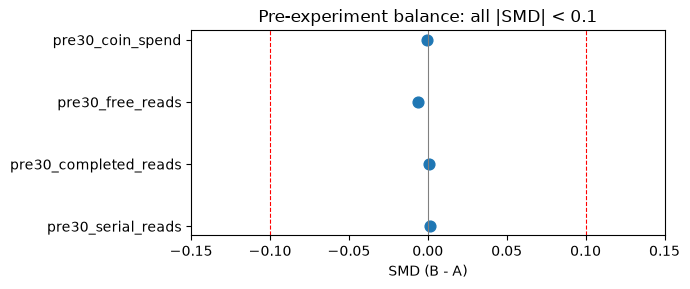

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3))
ax.scatter(num_balance["SMD"], num_balance["컬럼"], s=60)
ax.axvline(0, color="gray", linewidth=0.8)
ax.axvline(SMD_THRESHOLD, color="red", linestyle="--", linewidth=0.8)
ax.axvline(-SMD_THRESHOLD, color="red", linestyle="--", linewidth=0.8)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("SMD (B - A)")
ax.set_title("Pre-experiment balance: all |SMD| < 0.1")
plt.tight_layout()
plt.show()

**사전 균형 결과**
- 숫자 컬럼 4개: 모든 |SMD| < 0.01 (기준 0.1) → 균형
- 범주 컬럼 4개: 그룹 간 비율 차이 최대 0.28%p (acquisition_channel), 카이제곱 p 모두 > 0.05 → 균형
- 참고: t-검정 p도 모두 0.05 이상이나, 표본이 커서 판단 기준으로는 SMD를 사용

### 라운드 2 결론
- [x] SRM 없음 (p = 1.0)
- [x] 사전 균형 확인 (|SMD| < 0.1, 범주 비율 차이 < 0.3%p)
- → 배정은 정상적으로 이뤄졌고, 두 그룹은 실험 전 행동이 같은 집단으로 판단

**라운드 1 의문 중**
- 해결: ② 배정이 제대로 됐는가 → SRM 없음 / ③ 실험 전에 비슷한 사람들이었나 → 균형 확인
- 남음: ① 차이가 우연인가 / ④ 체험 시작자 비교의 선택 편향 / ⑤ 어떤 전환율로 판단할 것인가 → 라운드 3

## 라운드 3. 재검토: 첫인상은 우연인가, 그리고 어떤 기준으로 봐야 하는가

### 라운드 2까지 확인된 것
- 배정 정상 (SRM 없음), 두 그룹은 실험 전 동일한 집단 (사전 균형)
- 따라서 실험 이후의 차이는 체험 기간(7일 vs 14일)의 영향으로 볼 수 있는 상태

### 이번 라운드의 질문
1. 라운드 1에서 본 전환율 차이는 우연으로 설명되는가
2. 체험 시작률이 다르다면, 체험 시작자끼리 비교하는 것이 공정한가 (선택 편향)
3. 출시 판단에는 어떤 전환율을 써야 하는가

---

### 3-1. 검정 방법 선택

**지표 특성**
- 전환 여부는 유저마다 0 또는 1 → 두 그룹의 비율 비교 문제

**후보 방법**

| 방법 | 판단 |
| --- | --- |
| 두 비율 z-검정 | ✅ 채택. 그룹당 1만 명 이상으로 정규근사 충분, 차이의 방향·크기를 바로 제시 |
| 카이제곱 독립성 검정 | △ 2×2에서는 z-검정과 p-value 동일. 차이의 크기·신뢰구간을 따로 구해야 함 |
| Fisher 정확 검정 | ✗ 표본이 작을 때 쓰는 방법. 본 실험 규모에서는 불필요 |
| 로지스틱 회귀 | 라운드 5(세그먼트 분석)에서 사용 |

**p-value만으로 판단하지 않는 이유**
- p-value는 "차이가 0인가"만 알려줌. 차이가 얼마나 큰지는 알려주지 않음
- 신뢰구간을 함께 제시해 "진짜 차이가 있을 법한 범위"를 확인
- 신뢰구간이 0을 포함하면 차이가 없다는 가능성을 배제할 수 없음
- 신뢰구간을 실험 설계 시 정한 MDE(2%p)와 비교해 사업적으로 의미 있는 크기인지 판단

---

### 3-2. 선택 편향 점검

**문제 제기**
- 소개 화면에 "7일 무료" / "14일 무료"가 노출됨 → 체험 기간 자체가 체험 시작 여부에 영향 가능
- B가 체험을 더 많이 끌어왔다면, B 체험 시작자에는 "7일이었다면 체험하지 않았을 사람"이 섞여 있음
- 이 경우 A·B 체험 시작자는 같은 집단이 아님 → 체험 시작자끼리 비교하면 배정의 무작위성이 깨짐

**확인 방법**
- 체험 시작률을 두 비율 z-검정으로 비교
- 유의한 차이가 있으면 선택 편향 가능성 → 노출자 기준 전환율로 결론이 같은지 확인 (실험 설계서 7장 4번)

---

### 3-3. 두 전환율이 답하는 질문

| 지표 | 분모 | 답하는 질문 | 무작위 배정 유지 |
| --- | --- | --- | --- |
| 체험 시작자 기준 전환율 | 체험 시작자 | 체험을 시작한 사람 중 몇 %가 결제하는가 | ✗ 배정 이후 행동(체험 시작)으로 분모를 거름 |
| 노출자 기준 전환율 | 소개 화면 노출자 전원 | B로 출시하면 노출된 유저 중 결제하는 사람이 늘어나는가 | ✅ 배정된 전원을 그대로 비교 |

- 노출자 기준은 배정된 사람 전원을 비교하므로 무작위 배정의 공정성이 그대로 유지됨
- 실무에서는 이를 ITT(Intention-To-Treat, 배정 기준 분석)라고 부름
- 체험 시작자 기준은 "체험 이후 경험의 질"을 진단하는 보조 지표로 활용

In [12]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ALPHA = 0.05      # 유의수준
MDE = 2.0         # 최소 검출 효과 (%p, 실험 설계서 6장)

def two_prop_test(name, success_a, n_a, success_b, n_b):
    """두 그룹 비율 차이(B - A)의 z-검정과 95% 신뢰구간"""
    rate_a, rate_b = success_a / n_a, success_b / n_b

    # z-검정 (B, A 순서로 넣어야 z가 B - A 방향)
    z, p = proportions_ztest([success_b, success_a], [n_b, n_a])

    # 차이(B - A)의 95% 신뢰구간
    ci_low, ci_high = confint_proportions_2indep(success_b, n_b, success_a, n_a,
                                                 method="wald", alpha=ALPHA)

    return {
        "지표": name,
        "A(%)": rate_a * 100,
        "B(%)": rate_b * 100,
        "차이(%p)": (rate_b - rate_a) * 100,
        "상대 uplift(%)": (rate_b - rate_a) / rate_a * 100,
        "95% CI 하한(%p)": ci_low * 100,
        "95% CI 상한(%p)": ci_high * 100,
        "z": z,
        "p-value": p,
        "유의": "OK" if p < ALPHA else "-",
    }

In [13]:
# ── 그룹별 인원 ──
exposed = base.groupby("variant")["user_id"].count()                                # 노출자
trial   = base.groupby("variant")["start_trial"].sum()                              # 체험 시작자
paid    = base.groupby("variant")["converted"].sum()                                # 결제자

# ── 지표 3개를 같은 함수로 검정 ──
test_results = pd.DataFrame([
    two_prop_test("체험 시작 기준 전환율", paid["A"], trial["A"],   paid["B"], trial["B"]),
    two_prop_test("체험 시작률",          trial["A"], exposed["A"], trial["B"], exposed["B"]),
    two_prop_test("노출 기준 전환율",      paid["A"], exposed["A"], paid["B"], exposed["B"]),
]).set_index("지표")

test_results.round(3)

,A(%),B(%),차이(%p),상대 uplift(%),95% CI 하한(%p),95% CI 상한(%p),z,p-value,유의
지표,,,,,,,,,
체험 시작 기준 전환율,29.230,28.808,-0.421,-1.442,-1.524,0.681,-0.749,0.454,-
체험 시작률,7.826,8.767,0.941,12.026,0.749,1.134,9.574,0.000,OK
노출 기준 전환율,2.288,2.526,0.238,10.411,0.131,0.345,4.360,0.000,OK


### 라운드 3 결과

**3-1. 주요 지표 (체험 시작 기준 전환율)**
- A 29.23% vs B 28.81%, 차이 -0.42%p, 95% CI [-1.52, +0.68], p = 0.45
- 신뢰구간이 0을 포함 → 우연으로 설명 가능한 차이, 유의하지 않음
- 신뢰구간 전체가 MDE(±2%p) 안에 있음 → 설계 시 의미 있다고 본 크기의 차이는 없다고 판단

**3-2. 선택 편향 점검 (체험 시작률)**
- A 7.83% vs B 8.77%, 차이 +0.94%p (상대 +12.0%), p < 0.001
- "14일 무료" 문구가 체험 시작을 유의하게 늘림
- → A·B 체험 시작자는 같은 집단이 아님. 체험 시작자 기준 비교에는 선택 편향이 존재

**3-3. 노출 기준 전환율 (배정 기준 비교)**
- A 2.29% vs B 2.53%, 차이 +0.24%p (상대 +10.4%), 95% CI [+0.13, +0.35], p < 0.001
- 배정된 전원을 비교하는 지표에서는 B가 유의하게 높음

**종합**
- 체험 시작자 기준: 차이 없음 / 노출자 기준: B 우세 → 기준에 따라 결론이 다름
- 노출자 기준이 무작위 배정을 유지하는 비교이므로 "B가 결제자 수를 늘린다"는 결론이 더 신뢰할 만함
- 증가 경로: B는 체험 시작자를 늘렸고(+12%), 체험 후 결제 비율은 A와 차이가 없음 → 결제자 수 증가

**실험 설계에 대한 회고**
- 설계 시 주요 지표를 체험 시작자 기준으로 정했으나, 체험 기간 문구가 체험 시작에 영향을 주는 구조에서는 선택 편향에 취약
- 설계서 7장의 선택 편향 확인 절차 덕분에 이를 발견할 수 있었음
- 다음 설계에서는 노출자 기준 전환율을 주요 지표로 두는 것이 적절

**남은 의문 → 라운드 4**
- 결제자 수는 늘었지만, B 결제자가 빨리 해지하거나 코인 결제가 줄었다면 매출은 오히려 줄 수도 있음
- 전환율만으로 출시를 결정해도 되는가 → 가드레일(해지율, 60일 매출) 확인 필요

## 라운드 4. 가드레일: 결제자가 늘어난 대가로 망가진 것은 없는가

### 라운드 3까지의 결론
- 노출자 기준 전환율은 B가 유의하게 높음 (+0.24%p, 상대 +10.4%) → B는 결제자 수를 늘림

### 이번 라운드의 질문
- 늘어난 결제자가 금방 해지한다면?
- 패스 때문에 코인 결제가 줄었다면? (잠식효과)
- 결국 매출은 늘었는가, 줄었는가

### 가드레일 지표 (실험 설계서 5장)

| 지표 | 정의 | 판단 기준 |
| --- | --- | --- |
| 첫 달 해지율 | 유료 전환자 중 2회차 결제 전 해지 비율 | 3%p 이상 악화 시 출시 보류 (설계서 8장) |
| 60일 총매출 | 체험 시작자 1인당 60일간 패스 + 코인 결제액 | 유의한 감소 시 A 유지 (설계서 8장) |

---

### 4-1. 유저 표에 컬럼 추가

**첫 달 해지 정의 방법**
- 설계서 정의: 유료 전환자 중 2회차 결제 전에 해지
- 관찰 기간 60일 안에 2회차 결제일이 모두 포함됨 (A: D7·D37, B: D14·D44)
- 따라서 "전환했는데 결제가 1회뿐"인 유저 = 첫 달 해지자
- 결제 횟수로 정의한 뒤, 실제 cancel 이벤트와 교차 확인

**매출 컬럼**
- pass_rev: 유저별 결제 금액 합계
- coin_rev: 유저별 코인 수 합계 × 100원
- total_rev: pass_rev + coin_rev
- 기록이 없으면 0원 (결제·코인 사용을 하지 않은 것)
- 코인·열람 기록은 데이터 생성 시 체험 시작 후 60일 이내만 수집됨 → 별도 기간 필터 불필요

---

### 4-2. 첫 달 해지율 검정
- 비율 지표 → 라운드 3의 두 비율 z-검정 함수 재사용
- 분모: 유료 전환자

---

### 4-3. 60일 총매출 검정

**데이터 특성**
- 패스 매출은 결제자만 발생 (체험 시작자의 약 70%는 0원)
- 코인 매출은 소수 헤비 유저에게 몰림
- → 총매출은 0원은 드물지만 오른쪽 꼬리가 긴 분포

**후보 방법**

| 방법 | 비교 대상 | 판단 |
| --- | --- | --- |
| Welch t-검정 | 평균 | △ 표본이 커서 평균 비교에는 사용 가능. 교차 확인용 |
| 부트스트랩 | 평균 (분포 가정 없음) | ✅ 채택 (설계서 7장). 리샘플링으로 신뢰구간을 직접 구함 |
| Mann-Whitney U | 순위·분포 위치 | ✗ 평균이 아닌 "대체로 누가 더 큰가"를 비교. 매출 판단에는 평균(총액)이 필요 |
| 로그 변환 후 t-검정 | 기하평균 | ✗ 질문이 바뀜. 0원 처리 문제도 있음 |

**평균을 보는 이유**
- 회사 매출 = 1인당 평균 매출 × 유저 수 → 출시 판단에 필요한 것은 평균

**부트스트랩 원리**
- 각 그룹에서 같은 인원을 복원 추출(중복 허용)로 다시 뽑아 평균 차이를 계산
- 이를 2,000번 반복해 평균 차이의 분포를 만들고, 가운데 95% 구간을 신뢰구간으로 사용
- 정규분포 가정 없이 데이터 자체로 불확실성을 추정

**시행착오 포인트**
- t-검정과 부트스트랩을 모두 실행해 결과가 일치하는지 확인
- 일치하면 표본이 충분히 커서 t-검정의 가정도 문제없었다는 근거

**매출 분해**
- 총매출이 달라졌다면 패스 매출과 코인 매출 중 어디서 생긴 차이인지 분리 확인 (잠식효과 확인)

---

### 4-4. 라운드 3 교훈 적용: 선택 편향 주의
- 설계서의 가드레일 매출은 체험 시작자 기준 → 라운드 3에서 확인한 선택 편향이 그대로 적용될 수 있음
- 배정 기준(노출자 전원) 비교도 함께 확인
- 단, 코인 기록은 체험 시작자만 수집됨 → 노출자 기준으로는 패스 매출만 비교 가능 (데이터 수집 범위의 한계)

In [15]:
events = table_info["subscription_events"]
coins = table_info["coin_transactions"]

# ── 결제: 유저별 결제 횟수와 패스 매출 ──
pay = (events[events["event_type"] == "payment"]
       .groupby("user_id")
       .agg(n_payments=("event_type", "size"),
            pass_rev=("amount_krw", "sum")))

# ── 해지: 유저별 cancel 이벤트 수 (교차 확인용) ──
cancel = (events[events["event_type"] == "cancel"]
          .groupby("user_id").size()
          .rename("n_cancel"))

# ── 코인: 유저별 코인 매출 (1코인 = 100원) ──
coin = (coins.groupby("user_id")["coins"].sum() * 100).rename("coin_rev")

# ── 유저 표에 붙이기 (뼈대 base 기준 left) ──
user_df = (base
           .merge(pay, on="user_id", how="left")
           .merge(cancel, on="user_id", how="left")
           .merge(coin, on="user_id", how="left"))

new_cols = ["n_payments", "pass_rev", "n_cancel", "coin_rev"]
user_df[new_cols] = user_df[new_cols].fillna(0).astype(int)   # 기록 없음 = 0

user_df["total_rev"] = user_df["pass_rev"] + user_df["coin_rev"]
user_df["churn_m1"] = ((user_df["converted"] == 1) & (user_df["n_payments"] == 1)).astype(int)

print(f"행 수: {len(user_df):,}")

# ── 교차 확인: 첫 달 해지자(결제 1회)는 실제로 cancel 이벤트가 있는가 ──
converted_users = user_df[user_df["converted"] == 1]
pd.crosstab(converted_users["churn_m1"], converted_users["n_cancel"] > 0,
            rownames=["churn_m1 (결제 1회)"], colnames=["cancel 이벤트 있음"])

행 수: 314,922


cancel 이벤트 있음,False,True
churn_m1 (결제 1회),,
0,4954,532
1,0,2093


In [16]:
##첫달 해지율 확인

churned = converted_users.groupby("variant")["churn_m1"].sum()
paid_n  = converted_users.groupby("variant")["churn_m1"].count()

churn_result = pd.DataFrame([
    two_prop_test("첫 달 해지율", churned["A"], paid_n["A"], churned["B"], paid_n["B"])
]).set_index("지표")

churn_result.round(3)

,A(%),B(%),차이(%p),상대 uplift(%),95% CI 하한(%p),95% CI 상한(%p),z,p-value,유의
지표,,,,,,,,,
첫 달 해지율,26.818,28.338,1.52,5.666,-0.494,3.533,1.478,0.14,-


count    26128.0
mean     10696.0
std       8532.0
min          0.0
25%       4100.0
50%       7400.0
75%      15900.0
max      52200.0
Name: total_rev, dtype: float64
총매출 0원 비율: 0.01%
패스 매출 0원 비율: 70.99%


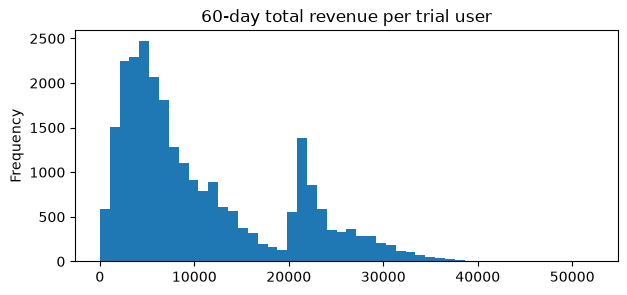

,A 평균(원),B 평균(원),차이(원),상대 차이(%),부트스트랩 95% CI 하한,부트스트랩 95% CI 상한,Welch t p-value,유의
지표,,,,,,,,
60일 총매출,10895.6,10517.4,-378.2,-3.5,-577.2,-165.2,0.0,✅
└ 패스 매출,5011.5,4895.9,-115.6,-2.3,-308.2,81.4,0.2,-
└ 코인 매출,5884.2,5621.6,-262.6,-4.5,-359.3,-165.5,0.0,✅


In [18]:
from scipy.stats import ttest_ind

trial_df = user_df[user_df["start_trial"] == 1]

print(trial_df["total_rev"].describe().round(0))
print(f"총매출 0원 비율: {(trial_df['total_rev'] == 0).mean():.2%}")
print(f"패스 매출 0원 비율: {(trial_df['pass_rev'] == 0).mean():.2%}")

trial_df["total_rev"].plot(kind="hist", bins=50, figsize=(7, 3),
                           title="60-day total revenue per trial user")
plt.show()


N_BOOT = 2000
rng = np.random.default_rng(42)

def compare_means(name, df, col):
    """B - A 평균 차이: Welch t-검정과 부트스트랩 95% CI"""
    a = df.loc[df["variant"] == "A", col].to_numpy()
    b = df.loc[df["variant"] == "B", col].to_numpy()
    diff = b.mean() - a.mean()

    # Welch t-검정 (두 그룹 분산이 달라도 되는 t-검정)
    t_p = ttest_ind(b, a, equal_var=False).pvalue

    # 부트스트랩: 그룹별로 복원 추출 → 평균 차이를 N_BOOT번 계산
    boot = np.array([
        rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean()
        for _ in range(N_BOOT)
    ])
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    return {
        "지표": name,
        "A 평균(원)": a.mean(),
        "B 평균(원)": b.mean(),
        "차이(원)": diff,
        "상대 차이(%)": diff / a.mean() * 100,
        "부트스트랩 95% CI 하한": ci_low,
        "부트스트랩 95% CI 상한": ci_high,
        "Welch t p-value": t_p,
        "유의": "✅" if (ci_low > 0 or ci_high < 0) else "-",   # CI가 0을 포함하지 않으면 유의
    }

# ── 총매출 + 분해(패스 / 코인) ──
rev_results = pd.DataFrame([
    compare_means("60일 총매출", trial_df, "total_rev"),
    compare_means("  └ 패스 매출", trial_df, "pass_rev"),
    compare_means("  └ 코인 매출", trial_df, "coin_rev"),
]).set_index("지표")

rev_results.round(1)

In [19]:
# 노출자 전원 기준 1인당 패스 매출 (체험 안 한 유저는 0원)
itt_pass = pd.DataFrame([
    compare_means("노출자 1인당 패스 매출", user_df, "pass_rev")
]).set_index("지표")

itt_pass.round(1)

,A 평균(원),B 평균(원),차이(원),상대 차이(%),부트스트랩 95% CI 하한,부트스트랩 95% CI 상한,Welch t p-value,유의
지표,,,,,,,,
노출자 1인당 패스 매출,392.2,429.2,37.0,9.4,18.5,54.8,0.0,✅


### 라운드 4 결과

**4-2. 첫 달 해지율**
- A 26.82% vs B 28.34%, 차이 +1.52%p, p = 0.14
- 통계적으로 유의하지 않고, 출시 보류 기준(3%p 악화)에도 미달 → 가드레일 통과

**4-3. 60일 총매출 (체험 시작자 기준)**
- A 10,896원 vs B 10,517원, 차이 -378원 (-3.5%)
- 부트스트랩 95% CI가 0을 포함하지 않음, Welch t-검정 p = 0.0003 → 유의한 감소
- 두 방법의 결론이 일치 → 표본이 커서 t-검정의 정규성 가정도 문제없었던 것으로 판단
- 분해 결과: 패스 매출 차이는 유의하지 않고, 감소분 대부분이 코인 매출(-263원)에서 발생
- → 14일 패스 기간 동안 대기 건너뛰기·완결작 회차 코인 구매가 패스로 대체된 잠식효과로 추정

**4-4. 배정 기준 비교**
- 노출자 1인당 패스 매출: A 392원 vs B 429원, +37원 (+9.4%), 유의
- 배정 기준으로는 B가 패스 매출을 늘림 (결제자 증가 효과)
- 단, 체험 미시작자의 코인 기록이 수집되지 않아 노출자 기준 총매출은 비교 불가 → 데이터 수집 범위의 한계

**종합**
- 해지율: 가드레일 통과
- 매출: 체험 시작자 기준 총매출은 B가 유의하게 낮음, 원인은 코인 매출 감소
- 다만 체험 시작자 기준 비교에는 라운드 3의 선택 편향이 섞여 있음
  - B 체험 시작자에는 관심이 덜한 유저가 더 포함 → 1인당 매출이 낮게 나올 수 있음
  - 코인 감소가 "패스 잠식" 때문인지 "체험자 구성 변화" 때문인지 이 비교만으로는 분리 불가

**남은 의문 → 라운드 5**
- 전체 평균 뒤에 서로 다르게 반응한 집단이 숨어 있지 않은가
- 읽기 패턴(연재 추격형·완결 정주행형·탐색형)별로 B의 효과가 다른가